# 03 — Fine-Tuning des modèles sur HAM10000

**Projet :** classification de sept catégories de lésions cutanées avec ResNet50, EfficientNet-B0 et ViT-B/16.

**Objectif du notebook :** entraîner trois architectures pré-entraînées sur ImageNet, sélectionner leurs meilleurs poids sur la **validation**.

**Protocole expérimental :**

- **Train :** 7 012 images — **Validation :** 1 501 images — **Test :** 1 502 images.
- Les partitions ont été construites dans `02_DataPreprocessing.ipynb` en respectant les identifiants `lesion_id` pour éviter les fuites entre ensembles.
- Le jeu **Test n'intervient jamais** dans l'optimisation, l'EarlyStopping ou la sélection des checkpoints.
- **Critère principal de sélection :** macro-F1 sur Validation, approprié au déséquilibre des sept classes.
- Les trois modèles sont entraînés **successivement**, avec un maximum de 30 époques et une patience d'EarlyStopping de 5.

## 1. Environnement, bibliothèques et reproductibilité

In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image


# 1. Reproductibilité des expériences
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# 2. Configuration du GPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# 3. Chemin des images HAM10000
DATA_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000"
)

IMAGES_DIR = DATA_DIR / "images"

# 4. Chemin des fichiers du notebook 02
PREPROCESSING_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham10000-datasplits/ham10000_Portfolio"
)

SPLITS_DIR = PREPROCESSING_DIR / "splits"
CONFIG_PATH = PREPROCESSING_DIR / "data_config.json"


# 5. Dossier de sauvegarde des résultats
OUTPUT_ROOT = Path("/kaggle/working/ham10000_Portfolio")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


# 6. Paramètres des images
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

CLASS_TO_IDX = {
    classe: i for i, classe in enumerate(CLASSES)
}

IMAGE_SIZE = 224

# Normalisation ImageNet
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


# 7. Afficher la configuration
print("PyTorch :", torch.__version__)
print("Device :", DEVICE)
print("Images :", IMAGES_DIR)
print("Partitions :", SPLITS_DIR)
print("Résultats :", OUTPUT_ROOT)

PyTorch : 2.11.0+cu128
Device : cuda
Images : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000/images
Partitions : /kaggle/input/datasets/imaneelqoraychy/ham10000-datasplits/ham10000_Portfolio/splits
Résultats : /kaggle/working/ham10000_Portfolio


## 2. Retrouver et vérifier les partitions de `02_Data_Preprocessing.ipynb`

In [2]:
import hashlib

# 1. Charger les métadonnées et la configuration
metadata = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = json.load(file)

# Vérifier la cohérence des classes
assert config["classes"] == CLASSES
assert config["class_to_idx"] == CLASS_TO_IDX
assert metadata["image_id"].is_unique


# 2. Charger les partitions
parts = {}

for name in ["train", "val", "test"]:

    part = pd.read_csv(SPLITS_DIR / f"{name}.csv")

    # Vérifier les colonnes et les labels
    required = ["image_id", "lesion_id", "dx", "label"]
    assert set(required).issubset(part.columns)
    assert part["image_id"].is_unique
    assert part["label"].eq(
        part["dx"].map(CLASS_TO_IDX)
    ).all()

    # Construire les chemins sans ouvrir les images
    part["image_path"] = part["image_id"].apply(
        lambda image_id: str(IMAGES_DIR / f"{image_id}.jpg")
    )

    parts[name] = part

    print(f"{name} : {len(part)} images")


# 3. Vérifier l'absence de Data Leakage
for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    assert set(parts[a]["lesion_id"]).isdisjoint(
        set(parts[b]["lesion_id"])
    )

    assert set(parts[a]["image_id"]).isdisjoint(
        set(parts[b]["image_id"])
    )

# Vérifier que toutes les images sont réparties
all_ids = pd.concat(parts.values())["image_id"]

assert all_ids.is_unique
assert set(all_ids) == set(metadata["image_id"])


# 4. Vérifier les Class Weights
train_counts = (
    parts["train"]["label"]
    .value_counts()
    .reindex(range(len(CLASSES)), fill_value=0)
)

assert (train_counts > 0).all()

expected_weights = (
    len(parts["train"]) / (len(CLASSES) * train_counts)
).to_numpy()

saved_weights = np.array([
    config["class_weights_train_only"][classe]
    for classe in CLASSES
])

assert np.allclose(expected_weights, saved_weights)


# 5. Signature du Train
train_ids = sorted(parts["train"]["image_id"].astype(str))

signature = hashlib.sha256(
    "|".join(train_ids).encode()
).hexdigest()


print("\nAucune fuite de données.")
print("Class Weights.")
print("Signature Train :", signature[:16])

train : 7012 images
val : 1501 images
test : 1502 images

Aucune fuite de données.
Class Weights.
Signature Train : a28bdeff87aac360


In [3]:
# Afficher la graine utilisée pour le GroupSplit
print("Graine du GroupSplit :", config["seed_split_selected"])

# Afficher la signature de Train
print("Signature Train :", signature[:16])

# Afficher les poids de chaque classe
print("\nClass Weights :")

for classe, poids in config["class_weights_train_only"].items():
    print(f"{classe} : {poids:.4f}")

Graine du GroupSplit : 71
Signature Train : a28bdeff87aac360

Class Weights :
akiec : 4.3935
bcc : 2.6292
bkl : 1.3482
df : 13.3562
mel : 1.2793
nv : 0.2131
vasc : 9.9180


- Les classes minoritaires, comme df et vasc, reçoivent des poids plus élevés, tandis que la classe majoritaire nv reçoit un poids plus faible. 
- Ces poids sont calculés uniquement à partir des données d'entraînement (Train).

## 3. Préparation des images et DataLoaders

### 3.1. Classe `HAM10000Dataset`

In [4]:
class HAM10000Dataset(Dataset):

    def __init__(self, frame, training=False):

        # Stocker les informations des images
        self.frame = frame.reset_index(drop=True)

        # Transformations communes à tous les ensembles
        transformations = [
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
        ]

        # Augmentation appliquée uniquement à Train
        if training:
            transformations += [
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.5),
                transforms.ColorJitter(
                    brightness=0.05,
                    contrast=0.05
                )
            ]

        # Conversion en tenseur et normalisation ImageNet
        transformations += [
            transforms.ToTensor(),
            transforms.Normalize(mean=MEAN, std=STD)
        ]

        self.transform = transforms.Compose(transformations)


    def __len__(self):
        # Retourner le nombre d'images
        return len(self.frame)


    def __getitem__(self, idx):

        # Récupérer les informations d'une image
        row = self.frame.iloc[idx]

        # Ouvrir l'image et appliquer les transformations
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        # Récupérer le label numérique
        label = int(row["label"])

        return image, label

- Nous créons une classe PyTorch pour lire les images HAM10000, les convertir en RGB, les redimensionner en `224 × 224`, les convertir en tenseurs et appliquer la normalisation ImageNet.

- **Data Augmentation : sur Train uniquement** : retournements horizontaux et verticaux aléatoires, puis légère variation de luminosité et de contraste. Validation et Test reçoivent uniquement les transformations déterministes, pour que leurs métriques soient comparables.

### 3.2. Contrôle d'un exemple

In [5]:
# Créer un Dataset à partir de Train
train_dataset = HAM10000Dataset(
    parts["train"],
    training=True
)

# Charger une image et son label
image, label = train_dataset[0]

print("Nombre d'images :", len(train_dataset))
print("Dimensions du tenseur :", image.shape)
print("Label :", label)
print("Classe :", CLASSES[label])

Nombre d'images : 7012
Dimensions du tenseur : torch.Size([3, 224, 224])
Label : 5
Classe : nv


### 3.3. Premier contrôle des DataLoaders

In [6]:
# 1. Créer les datasets
train_dataset = HAM10000Dataset(parts["train"], training=True)
val_dataset = HAM10000Dataset(parts["val"], training=False)
test_dataset = HAM10000Dataset(parts["test"], training=False)


# 2. Définir la taille des mini-batchs
BATCH_SIZE = 16


# 3. Créer le DataLoader d'entraînement
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)


# 4. Créer le DataLoader de validation
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)


# 5. Vérifier les DataLoader
print("Train :", len(train_dataset), "images")
print("Validation :", len(val_dataset), "images")
print("Test :", len(test_dataset), "images")

print("Mini-batchs Train :", len(train_loader))
print("Mini-batchs Validation :", len(val_loader))

Train : 7012 images
Validation : 1501 images
Test : 1502 images
Mini-batchs Train : 439
Mini-batchs Validation : 94


## 4. Modèles ImageNet et gestion des checkpoints

### 4.1. Construction des trois architectures

In [7]:
def build_model(architecture, pretrained=True):

    # 1. ResNet50
    if architecture == "resnet50":

        weights = (
            models.ResNet50_Weights.IMAGENET1K_V2
            if pretrained else None
        )

        model = models.resnet50(weights=weights)

        # Remplacer la couche finale par 7 sorties
        model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
        head = model.fc

    # 2. EfficientNet-B0
    elif architecture == "efficientnet_b0":

        weights = (
            models.EfficientNet_B0_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        model = models.efficientnet_b0(weights=weights)

        # Remplacer la couche de classification
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features,
            len(CLASSES)
        )
        head = model.classifier[-1]

    # 3. Vision Transformer
    elif architecture == "vit_b_16":

        weights = (
            models.ViT_B_16_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        model = models.vit_b_16(weights=weights)

        # Remplacer la tête de classification
        model.heads.head = nn.Linear(
            model.heads.head.in_features,
            len(CLASSES)
        )
        head = model.heads.head

    else:
        raise ValueError("Architecture inconnue.")

    return model, head

### 4.2. Réutilisation des meilleurs checkpoints

In [8]:
# Versions des poids ImageNet
WEIGHT_VERSION = {
    "resnet50": "IMAGENET1K_V2",
    "efficientnet_b0": "IMAGENET1K_V1",
    "vit_b_16": "IMAGENET1K_V1"
}

# Dossier où seront sauvegardés les modèles
MODELS_DIR = OUTPUT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)


# Fonction pour recharger un modèle entraîné
def load_checkpoint_model(architecture, checkpoint_path=None):

    # Définir le chemin du checkpoint
    if checkpoint_path is None:
        checkpoint_path = MODELS_DIR / f"{architecture}_best.pt"

    checkpoint_path = Path(checkpoint_path)

    # Vérifier que le fichier existe
    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint introuvable : {checkpoint_path}"
        )

    # Charger les paramètres sauvegardés
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Vérifier la compatibilité
    assert checkpoint["architecture"] == architecture
    assert checkpoint["classes"] == CLASSES
    assert checkpoint["image_size"] == IMAGE_SIZE

    # Reconstruire le modèle sans télécharger les poids ImageNet
    loaded_model, _ = build_model(
        architecture,
        pretrained=False
    )

    # Charger les paramètres fine-tunés
    loaded_model.load_state_dict(checkpoint["state_dict"])

    # Préparer le modèle pour l'évaluation
    loaded_model = loaded_model.to(DEVICE)
    loaded_model.eval()

    return loaded_model, checkpoint, checkpoint_path


print("Gestion des checkpoints configurée.")
print("Dossier :", MODELS_DIR)

Gestion des checkpoints configurée.
Dossier : /kaggle/working/ham10000_Portfolio/models


## 5. Paramètres des expériences

L'entraînement final repose sur les paramètres suivants :

| Paramètre | Valeur | Rôle |
|---|---|---|
| Maximum d'époques | `30` | Limite supérieure par architecture |
| EarlyStopping | `patience = 5` | Stopper si le macro-F1 de validation n'améliore plus suffisamment |
| Scheduler | `patience = 2` | Réduire le taux d'apprentissage lorsque la **loss de validation** stagne |
| Batch ResNet50 / EfficientNet-B0 / ViT | `16 / 24 / 8` | Adapter mémoire GPU et architecture |
| LR backbone / tête | `1e-5 / 1e-4` | Adapter les paramètres pré-entraînés plus prudemment que la nouvelle tête |
| Weight decay | `1e-4` | Régularisation AdamW |
| Amélioration minimale | `MIN_DELTA = 1e-4` | Seuil pour la sélection du checkpoint |

In [9]:
# Modèle à entraîner en premier
MODELS_TO_TRAIN = ["resnet50"]

# Nombre maximal d'époques
MAX_EPOCHS = 30

# EarlyStopping et scheduler
EARLY_STOPPING_PATIENCE = 5
SCHEDULER_PATIENCE = 2

# Batch size selon le modèle
BATCH_SIZE = {
    "resnet50": 16,
    "efficientnet_b0": 24,
    "vit_b_16": 8
}

# Chargement des données
NUM_WORKERS = 2

# Learning rates
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4

# Régularisation
WEIGHT_DECAY = 1e-4
MIN_DELTA = 1e-4

# Vérifications
assert set(MODELS_TO_TRAIN).issubset(WEIGHT_VERSION)
assert DEVICE.type == "cuda", "Active le GPU Kaggle."

print("Modèle sélectionné :", MODELS_TO_TRAIN)
print("Époques maximales :", MAX_EPOCHS)
print("EarlyStopping :", EARLY_STOPPING_PATIENCE)
print("GPU :", DEVICE)

Modèle sélectionné : ['resnet50']
Époques maximales : 30
EarlyStopping : 5
GPU : cuda


## 6. Entraînement et validation

### 6.1. Fonction `one_epoch()`

`one_epoch` parcourt les mini-batchs et agrège la perte, l'accuracy et le **macro-F1 sur les sept classes**.

In [10]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

def one_epoch(model, loader, criterion,
              optimizer=None, amp=False, scaler=None):

    # 1. Déterminer le mode : Train ou Validation
    is_train = optimizer is not None
    model.train(mode=is_train)

    total_loss = 0.0
    total_images = 0
    y_true = []
    y_pred = []

    # 2. Activer les gradients uniquement pendant Train
    context = (
        torch.enable_grad()
        if is_train else torch.no_grad()
    )

    with context:

        # 3. Parcourir tous les mini-batchs
        for images, labels in tqdm(
                    loader,
                    desc="Train" if is_train else "Validation",
                    leave=False
                ):

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            # 4. Prédictions et calcul de la loss
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            # 5. Mise à jour des paramètres : Train seulement
            if is_train:

                if amp:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()

                else:
                    loss.backward()
                    optimizer.step()

            # 6. Accumuler la perte et les prédictions
            batch_size = len(labels)

            total_loss += loss.item() * batch_size
            total_images += batch_size

            y_true.extend(labels.detach().cpu().tolist())
            y_pred.extend(
                outputs.argmax(dim=1).detach().cpu().tolist()
            )

    # 7. Calculer les métriques de l'époque
    return {
        "loss": total_loss / total_images,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=list(range(len(CLASSES))),
            average="macro",
            zero_division=0
        )
    }


print("Fonction one_epoch() définie avec succès.")

Fonction one_epoch() définie avec succès.


### 6.2. Fonction `train_architecture()`

Pour chacune des trois architectures, cette fonction :

1. Construit les DataLoaders Train et Validation à la taille de batch du modèle.

2. Charge les **poids ImageNet**, remplace la tête et transfère le réseau sur GPU.

3. Applique une `CrossEntropyLoss` **pondérée sur Train**, non pondérée sur Validation.

4. Configure **AdamW avec deux groupes de paramètres** : `BACKBONE_LR` et `HEAD_LR`.

5. Configure `ReduceLROnPlateau` sur la **loss de validation**.

6. Entraîne jusqu'à `MAX_EPOCHS`, évalue après chaque époque, puis applique l'**EarlyStopping sur le macro-F1 de validation**.

7. Enregistre le meilleur checkpoint lors d'une amélioration du macro-F1, conserve l'historique `.csv` après **chaque** époque et un bilan `.json` en fin d'expérience.

8. Libère les objets du modèle et le cache GPU avant l'architecture suivante.

In [11]:
import gc


def train_architecture(architecture):

    # 1. Vérifier l'architecture
    assert architecture in WEIGHT_VERSION

    # 2. Préparer les DataLoader
    train_loader = DataLoader(
        HAM10000Dataset(parts["train"], training=True),
        batch_size=BATCH_SIZE[architecture],
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader = DataLoader(
        HAM10000Dataset(parts["val"], training=False),
        batch_size=BATCH_SIZE[architecture],
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )

    # 3. Récupérer les Class Weights de Train
    class_weights = torch.tensor(
        [config["class_weights_train_only"][c] for c in CLASSES],
        dtype=torch.float32,
        device=DEVICE
    )

    # Loss pondérée pour Train, non pondérée pour Validation
    train_criterion = nn.CrossEntropyLoss(weight=class_weights)
    val_criterion = nn.CrossEntropyLoss()

    # 4. Charger le modèle pré-entraîné
    model, head = build_model(architecture, pretrained=True)
    model = model.to(DEVICE)

    # 5. Séparer les paramètres du backbone et de la tête
    head_ids = {id(p) for p in head.parameters()}

    optimizer = torch.optim.AdamW(
        [
            {
                "params": [
                    p for p in model.parameters()
                    if id(p) not in head_ids
                ],
                "lr": BACKBONE_LR
            },
            {
                "params": [
                    p for p in model.parameters()
                    if id(p) in head_ids
                ],
                "lr": HEAD_LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    # 6. Scheduler basé sur la loss de validation
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=SCHEDULER_PATIENCE
    )

    # 7. Mixed Precision sur GPU
    amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    # 8. Initialiser l'EarlyStopping
    best_f1 = -1.0
    best_val_loss = float("inf")
    stale = 0
    history = []

    # 9. Préparer les dossiers de sauvegarde
    training_dir = OUTPUT_ROOT / "training"
    training_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = MODELS_DIR / f"{architecture}_best.pt"
    history_path = training_dir / f"{architecture}_history.csv"

    # 10. Boucle des époques
    for epoch in range(1, MAX_EPOCHS + 1):

        # Entraînement
        train_metrics = one_epoch(
            model,
            train_loader,
            criterion=train_criterion,
            optimizer=optimizer,
            amp=amp,
            scaler=scaler
        )

        # Validation : aucune mise à jour des poids
        val_metrics = one_epoch(
            model,
            val_loader,
            criterion=val_criterion,
            amp=amp
        )

        # Ajuster le learning rate
        scheduler.step(val_metrics["loss"])

        # Enregistrer les métriques
        row = {
            "epoch": epoch,
            "train_weighted_loss": train_metrics["loss"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_accuracy": val_metrics["accuracy"],
            "lr_backbone": optimizer.param_groups[0]["lr"],
            "lr_head": optimizer.param_groups[1]["lr"]
        }

        history.append(row)

        # 11. Vérifier si le modèle s'améliore
        improved = (
            val_metrics["macro_f1"] > best_f1 + MIN_DELTA
            or (
                abs(val_metrics["macro_f1"] - best_f1) <= MIN_DELTA
                and val_metrics["loss"] < best_val_loss - MIN_DELTA
            )
        )

        if improved:
            best_f1 = float(val_metrics["macro_f1"])
            best_val_loss = float(val_metrics["loss"])
            best_epoch = epoch
            stale = 0

            # Sauvegarder uniquement le meilleur modèle
            torch.save(
                {
                    "architecture": architecture,
                    "classes": CLASSES,
                    "image_size": IMAGE_SIZE,
                    "weight_version": WEIGHT_VERSION[architecture],
                    "state_dict": {
                        k: v.detach().cpu()
                        for k, v in model.state_dict().items()
                    },
                    "best_epoch": best_epoch,
                    "best_val_macro_f1": best_f1,
                    "best_val_loss": best_val_loss,
                    "train_signature": signature,
                    "split_seed": config["seed_split_selected"],
                    "training_weighted_loss": True
                },
                checkpoint_path
            )

        else:
            stale += 1

        # 12. Afficher les résultats de l'époque
        print(
            f"{architecture} | Epoch {epoch:02d} | "
            f"Train Loss={train_metrics['loss']:.4f} | "
            f"Val Loss={val_metrics['loss']:.4f} | "
            f"Val Macro-F1={val_metrics['macro_f1']:.4f} | "
            f"Patience={stale}/{EARLY_STOPPING_PATIENCE}"
        )

        # Sauvegarder l'historique après chaque époque
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # 13. Arrêt anticipé
        if stale >= EARLY_STOPPING_PATIENCE:
            print("EarlyStopping : arrêt de l'entraînement.")
            break

    # 14. Résumé de l'expérience
    summary = {
        "architecture": architecture,
        "best_val_macro_f1": best_f1,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_completed": len(history),
        "checkpoint": checkpoint_path.name,
        "train_signature": signature
    }

    summary_path = training_dir / f"{architecture}_summary.json"

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    # 15. Libérer la mémoire
    del model, head, train_loader, val_loader
    del optimizer, scheduler, scaler

    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return summary


print("Fonction train_architecture() définie avec succès.")

Fonction train_architecture() définie avec succès.


## 7. Exécution des expériences

### 7.1. Test de fonctionnement (smoke test)

In [12]:
# Activer le test technique
SMOKE_TEST = False

if SMOKE_TEST:

    # Sauvegarder la configuration actuelle
    original_epochs = MAX_EPOCHS
    original_output = OUTPUT_ROOT
    original_models_dir = MODELS_DIR

    try:
        # Une seule époque par modèle
        MAX_EPOCHS = 1

        # Isoler les résultats du test
        OUTPUT_ROOT = original_output / "smoke_test"
        MODELS_DIR = OUTPUT_ROOT / "models"
        MODELS_DIR.mkdir(parents=True, exist_ok=True)

        # Libérer le modèle utilisé lors de la vérification
        if "model" in globals():
            del model

        if "head" in globals():
            del head

        gc.collect()
        torch.cuda.empty_cache()

        # Tester les trois architectures successivement
        smoke_results = []

        for architecture in [
            "resnet50",
            "efficientnet_b0",
            "vit_b_16"
        ]:
            print(f"\n===== TEST : {architecture} =====")

            summary = train_architecture(architecture)
            smoke_results.append(summary)

        # Résumé des trois tests
        display(pd.DataFrame(smoke_results))

        print("\nTests terminés avec succès.")

    finally:
        # Restaurer la configuration originale
        MAX_EPOCHS = original_epochs
        OUTPUT_ROOT = original_output
        MODELS_DIR = original_models_dir

### 7.2. Fine-Tuning final des trois architectures

In [13]:
# Entraînement définitif
MODELS_TO_TRAIN = [
    "resnet50",
    "efficientnet_b0",
    "vit_b_16"
]

MAX_EPOCHS = 30

# Libérer la mémoire GPU du test précédent
if "model" in globals():
    del model

if "head" in globals():
    del head

gc.collect()
torch.cuda.empty_cache()

# Lancer les trois entraînements successivement
training_summaries = []

for architecture in MODELS_TO_TRAIN:

    print(f"\n===== ENTRAÎNEMENT : {architecture} =====")

    summary = train_architecture(architecture)
    training_summaries.append(summary)

# Sauvegarder le résumé global
results = pd.DataFrame(training_summaries)

results.to_csv(
    OUTPUT_ROOT / "training_summary.csv",
    index=False
)

display(results)

print("\nEntraînements terminés.")


===== ENTRAÎNEMENT : resnet50 =====
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 150MB/s]


Train:   0%|          | 0/439 [00:00<?, ?it/s]

Validation:   0%|          | 0/94 [00:00<?, ?it/s]

resnet50 | Epoch 01 | Train Loss=1.7388 | Val Loss=1.1692 | Val Macro-F1=0.4489 | Patience=0/5


Train:   0%|          | 0/439 [00:00<?, ?it/s]

... (217 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d7080af7060>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d7080af7060>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

vit_b_16 | Epoch 16 | Train Loss=0.0034 | Val Loss=0.7281 | Val Macro-F1=0.7695 | Patience=5/5
EarlyStopping : arrêt de l'entraînement.


,architecture,best_val_macro_f1,best_val_loss,best_epoch,epochs_completed,checkpoint,train_signature
0,resnet50,0.707088,0.559246,16,21,resnet50_best.pt,a28bdeff87aac3605355c3e96d96f90a2c852df5616d1c...
1,efficientnet_b0,0.707474,0.564720,22,27,efficientnet_b0_best.pt,a28bdeff87aac3605355c3e96d96f90a2c852df5616d1c...
2,vit_b_16,0.785512,0.578952,11,16,vit_b_16_best.pt,a28bdeff87aac3605355c3e96d96f90a2c852df5616d1c...



Entraînements terminés.


- `models/<architecture>_best.pt` : meilleurs paramètres et métadonnées pour chaque architecture.
- `training/<architecture>_history.csv` : perte, accuracy, macro-F1 et learning rates par époque.
- `training/<architecture>_summary.json` : meilleure époque, meilleur macro-F1, durée de l'entraînement.
- `training_summary.csv` : tableau comparatif global.

## 8. Visualisation des performances
Chaque architecture possède une figure avec deux courbes :

1. La **Train Loss pondérée** et la **Validation Loss non pondérée** : utile pour observer leurs tendances dans le temps, mais pas pour interpréter directement l'écart des valeurs.
2. Le **macro-F1 de validation** : permet de suivre la généralisation et d'identifier la meilleure époque sélectionnée.

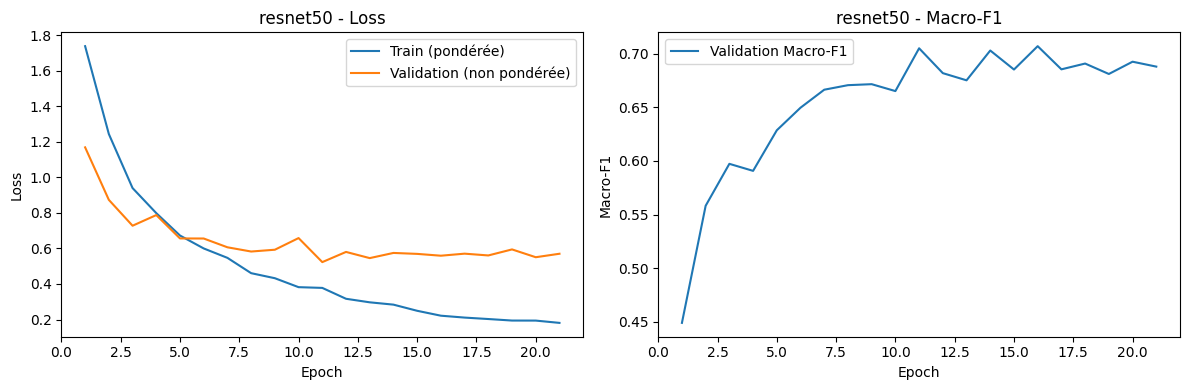

Figure sauvegardée : /kaggle/working/ham10000_Portfolio/figures/resnet50_learning_curves.png


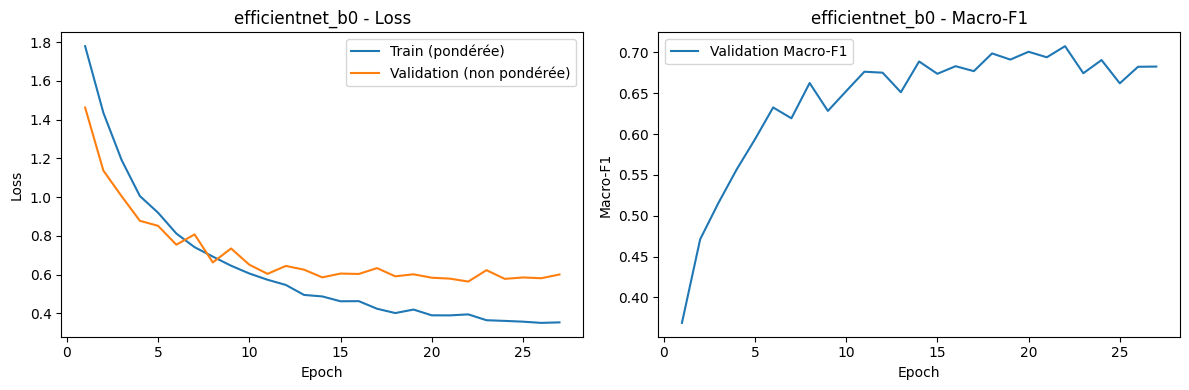

Figure sauvegardée : /kaggle/working/ham10000_Portfolio/figures/efficientnet_b0_learning_curves.png


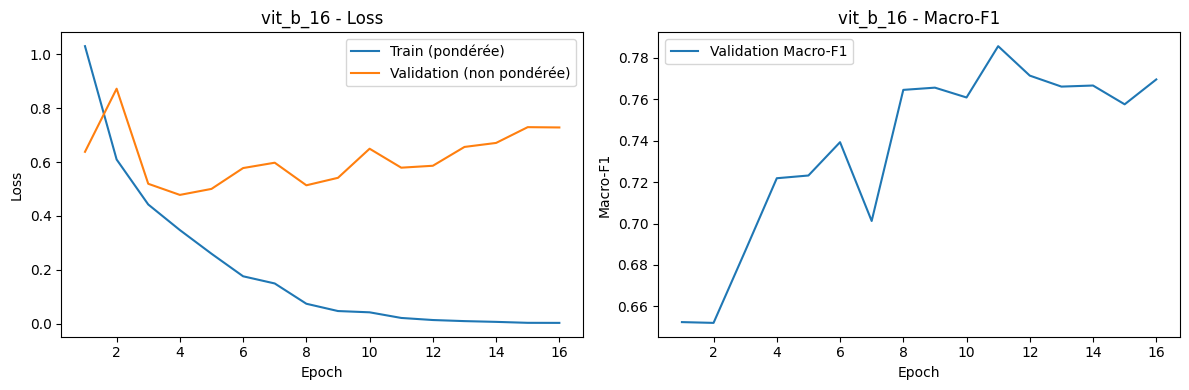

Figure sauvegardée : /kaggle/working/ham10000_Portfolio/figures/vit_b_16_learning_curves.png


In [14]:
# Créer le dossier des figures
FIGURES_DIR = OUTPUT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Tracer les résultats de chaque modèle
for architecture in MODELS_TO_TRAIN:

    # Charger l'historique d'entraînement
    history_path = (
        OUTPUT_ROOT / "training" /
        f"{architecture}_history.csv"
    )

    history = pd.read_csv(history_path)

    # Créer deux graphiques
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Graphique 1 : Loss
    axes[0].plot(
        history["epoch"],
        history["train_weighted_loss"],
        label="Train (pondérée)"
    )

    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        label="Validation (non pondérée)"
    )

    axes[0].set_title(f"{architecture} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # Graphique 2 : Macro-F1
    axes[1].plot(
        history["epoch"],
        history["val_macro_f1"],
        label="Validation Macro-F1"
    )

    axes[1].set_title(f"{architecture} - Macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro-F1")
    axes[1].legend()

    # Sauvegarder la figure
    plt.tight_layout()

    figure_path = (
        FIGURES_DIR /
        f"{architecture}_learning_curves.png"
    )

    plt.savefig(figure_path, dpi=180)
    plt.show()
    plt.close(fig)

    print("Figure sauvegardée :", figure_path)

## 9. Analyse scientifique des résultats obtenus

### 9.1. Comparaison des trois architectures sur Validation

Les valeurs ci-dessous proviennent du **tableau de résultats produit par l'entraînement enregistré dans ce notebook**, et non du Test Set.

| Architecture | Meilleur macro-F1 de validation | Loss de validation au meilleur macro-F1 | Meilleure époque | Époques réalisées |
|---|---:|---:|---:|---:|
| ResNet50 | **0,707088** (70,71 %) | 0,559246 | 16 | 21 |
| EfficientNet-B0 | **0,707474** (70,75 %) | 0,564720 | 22 | 27 |
| **ViT-B/16** | **0,773038** (78,55 %) | **0,578952** | **11** | **16** |

**Constat :** ViT-B/16 obtient le **meilleur macro-F1 de validation**, avec environ **7,80 points de pourcentage** de plus qu'EfficientNet-B0. ResNet50 et EfficientNet-B0 sont pratiquement à égalité, avec moins de 0,04 point d'écart. Ces valeurs décrivent les checkpoints sélectionnés sur Validation, **pas** leurs performances finales sur Test.

### 9.2. Lecture des courbes et surapprentissage

- **ResNet50 :** le macro-F1 progresse jusqu'à l'époque 16, puis varie sans nouveau record, arrêt anticipé à l'époque 21. La perte d'entraînement continue de diminuer alors que les performances de validation plafonnent, ce qui suggère un début de surapprentissage.
- **EfficientNet-B0 :** courbes globalement plus régulières, meilleur macro-F1 à l'époque 22, suivi d'un arrêt à l'époque 27.
- **ViT-B/16 :** le macro-F1 atteint son maximum à l'époque 11. La perte d'entraînement chute très fortement et la perte de validation remonte ensuite : **signes plus marqués de surapprentissage**. L'EarlyStopping préserve néanmoins le checkpoint de l'époque 11 et stoppe à l'époque 16.

Le choix du meilleur checkpoint **avant la dégradation** des performances est donc essentiel. Les différences entre pertes pondérée et non pondérée invitent à privilégier l'évolution du macro-F1 et des métriques adaptées plutôt qu'une comparaison brute des deux loss.

### 9.3. Limites et suite du protocole

- Le dataset HAM10000 est **fortement déséquilibré**, un macro-F1 global ne suffit pas pour juger la reconnaissance de chaque lésion.
- **Le rappel du mélanome (`mel`)**, les scores par classe, l'accuracy, les matrices de confusion et la robustesse doivent encore être examinés.
- Le modèle le mieux classé sur Validation n'est **pas automatiquement** le meilleur sur Test.
- Les résultats ne démontrent **aucune aptitude au diagnostic clinique**, ils sont ceux d'une expérience de classification d'images dans un cadre de portfolio.